In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from datetime import datetime, timedelta
from goes2go.accessors import rgbAccessor
from goes2go.data import goes_nearesttime, goes_timerange

In [2]:
DATE = datetime(2026, 1, 12, 12)
GOES_DIR = "./goes_data_cache"

### Basic example

In [3]:
g = goes_nearesttime(
    DATE, within=timedelta(hours=1), satellite="goes19", product="ABI", domain="F", save_dir=GOES_DIR
)

📦 Finished downloading [1] files to [goes_data_cache/noaa-goes19/ABI-L2-MCMIPF].
📚 Finished reading [1] files into xarray.Dataset.                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      

In [4]:
g

<xarray.Dataset> Size: 4GB
Dimensions:                                 (y: 5424, x: 5424,
                                             number_of_time_bounds: 2,
                                             number_of_image_bounds: 2, band: 1)
Coordinates: (12/41)
    t                                       datetime64[ns] 8B 2026-01-12T12:0...
  * y                                       (y) float32 22kB 0.1518 ... -0.1518
  * x                                       (x) float32 22kB -0.1518 ... 0.1518
    y_image                                 float32 4B 0.0
    x_image                                 float32 4B 0.0
    band_wavelength_C01                     (band) float32 4B 0.47
    ...                                      ...
    band_id_C15                             (band) int8 1B 15
    band_id_C16                             (band) int8 1B 16
    dataset_name                            <U74 296B 'OR_ABI-L2-MCMIPF-M6_G1...
    date_created                            <U22 88B '2026-01-12T12:10:00.0Z'
    time_coverage_start                     <U22 88B '2026-01-12T12:00:21.1Z'
    time_coverage_end                       <U22 88B '2026-01-12T12:09:52.5Z'
Dimensions without coordinates: number_of_time_bounds, number_of_image_bounds,
                                band
Data variables: (12/125)
    CMI_C01                                 (y, x) float32 118MB nan nan ... nan
    DQF_C01                                 (y, x) float32 118MB nan nan ... nan
    CMI_C02                                 (y, x) float32 118MB nan nan ... nan
    DQF_C02                                 (y, x) float32 118MB nan nan ... nan
    CMI_C03                                 (y, x) float32 118MB nan nan ... nan
    DQF_C03                                 (y, x) float32 118MB nan nan ... nan
    ...                                      ...
    std_dev_brightness_temperature_C16      float32 4B 13.79
    percent_uncorrectable_GRB_errors        float32 4B nan
    percent_uncorrectable_L0_errors         float32 4B 0.0
    dynamic_algorithm_input_data_container  int32 4B -2147483647
    algorithm_product_version_container     int32 4B -2147483647
    filename                                <U112 448B 'noaa-goes19/ABI-L2-MC...
Attributes: (12/26)
    naming_authority:          gov.nesdis.noaa
    Conventions:               CF-1.7
    Metadata_Conventions:      Unidata Dataset Discovery v1.0
    standard_name_vocabulary:  CF Standard Name Table (v35, 20 July 2016)
    institution:               DOC/NOAA/NESDIS > U.S. Department of Commerce,...
    project:                   GOES
    ...                        ...
    cdm_data_type:             Image
    processing_level:          National Aeronautics and Space Administration ...
    timeline_id:               ABI Mode 6
    production_data_source:    Realtime
    id:                        c81c381c-d537-414a-999a-6b47f9615595
    path:                      ['noaa-goes19/ABI-L2-MCMIPF/2026/012/12/OR_ABI...

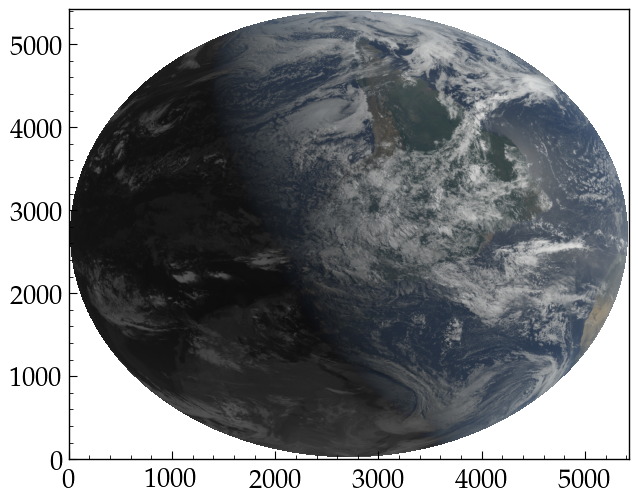

In [5]:
plt.imshow(g.rgb.TrueColor())

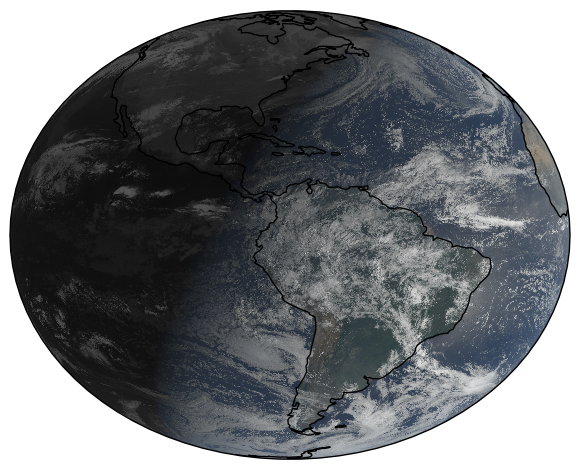

In [6]:
ax = plt.subplot(projection=g.rgb.crs)
ax.imshow(g.rgb.TrueColor(), **g.rgb.imshow_kwargs)
ax.coastlines()


### Mercartor projection for Brazil

In [7]:
# Define Brazil bounding box (lon_min, lon_max, lat_min, lat_max)
BRAZIL_EXTENT = [-75.0, -34.0, -35.0, 5.5]

In [8]:
# 3. Create True Color RGB
rgb_data = g.rgb.TrueColor()

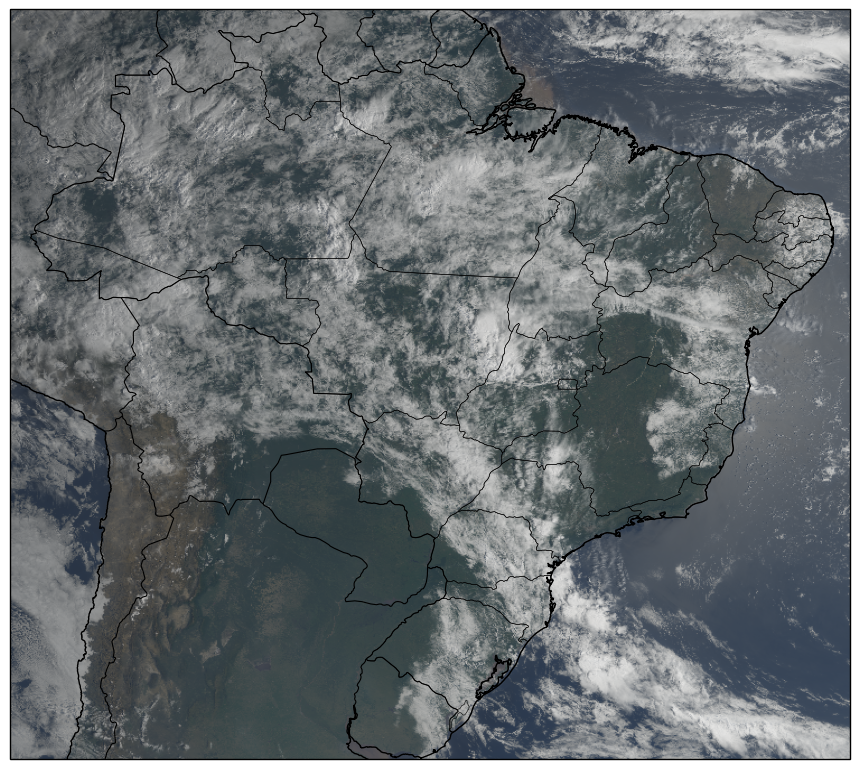

In [9]:
# 4. Plot in Mercator projection
fig = plt.figure(figsize=(12, 10))

ax = plt.axes(projection=ccrs.Mercator())
ax.set_extent(BRAZIL_EXTENT, crs=ccrs.PlateCarree())
# ax.set_extent(extents=[-170, 170, -90, 90], crs=ccrs.PlateCarree())
# GOES ABI data is in geostationary projection
im = ax.imshow(
    rgb_data,
    origin="upper",
    transform=ccrs.Geostationary(
        central_longitude=g.goes_imager_projection.longitude_of_projection_origin,
        satellite_height=g.goes_imager_projection.perspective_point_height
    )
)

# 5. Add map features
ax.coastlines(resolution="10m", linewidth=1)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)
ax.add_feature(cfeature.STATES, linewidth=0.4)

### Get GOES-19 data for a time range

In [10]:
df_files_abi = goes_timerange(
    start=DATE - timedelta(hours=1),
    end=DATE,
    satellite="goes19",
    product="ABI",
    domain="F",
    return_as="filelist",
    save_dir=GOES_DIR,
)

📦 Finished downloading [6] files to [goes_data_cache/noaa-goes19/ABI-L2-MCMIPF].


In [11]:
df_files_abi

,file,product_mode,satellite,start,end,creation,product,mode_bands,mode,band
0,noaa-goes19/ABI-L2-MCMIPF/2026/012/11/OR_ABI-L...,ABI-L2-MCMIPF-M6,G19,2026-01-12 11:00:21.100,2026-01-12 11:09:53.100,2026-01-12 11:09:59.800,ABI-L2-MCMIPF,M6,6,None
1,noaa-goes19/ABI-L2-MCMIPF/2026/012/11/OR_ABI-L...,ABI-L2-MCMIPF-M6,G19,2026-01-12 11:10:21.100,2026-01-12 11:19:53.100,2026-01-12 11:19:59.800,ABI-L2-MCMIPF,M6,6,None
2,noaa-goes19/ABI-L2-MCMIPF/2026/012/11/OR_ABI-L...,ABI-L2-MCMIPF-M6,G19,2026-01-12 11:20:21.100,2026-01-12 11:29:51.900,2026-01-12 11:29:59.400,ABI-L2-MCMIPF,M6,6,None
3,noaa-goes19/ABI-L2-MCMIPF/2026/012/11/OR_ABI-L...,ABI-L2-MCMIPF-M6,G19,2026-01-12 11:30:21.100,2026-01-12 11:39:53.100,2026-01-12 11:39:59.600,ABI-L2-MCMIPF,M6,6,None
4,noaa-goes19/ABI-L2-MCMIPF/2026/012/11/OR_ABI-L...,ABI-L2-MCMIPF-M6,G19,2026-01-12 11:40:21.100,2026-01-12 11:49:53.100,2026-01-12 11:49:59.900,ABI-L2-MCMIPF,M6,6,None
5,noaa-goes19/ABI-L2-MCMIPF/2026/012/11/OR_ABI-L...,ABI-L2-MCMIPF-M6,G19,2026-01-12 11:50:21.100,2026-01-12 11:59:53.100,2026-01-12 11:59:59.600,ABI-L2-MCMIPF,M6,6,None


In [12]:
df_files_abi.attrs

{'satellite': 'noaa-goes19',
 'product': 'ABI-L2-MCMIPF',
 'start': datetime.datetime(2026, 1, 12, 11, 0),
 'end': datetime.datetime(2026, 1, 12, 12, 0),
 'bands': None,
 'refresh': False,
 'ignore_missing': True,
 'filePath': './goes_data_cache'}

In [13]:
ds_list = [xr.open_dataset(f"{df_files_abi.attrs['filePath']}/{f}") for f in df_files_abi.file]

In [14]:
ds_list[0]

<xarray.Dataset> Size: 4GB
Dimensions:                                 (y: 5424, x: 5424,
                                             number_of_time_bounds: 2,
                                             number_of_image_bounds: 2, band: 1)
Coordinates: (12/37)
    t                                       datetime64[ns] 8B ...
  * y                                       (y) float32 22kB 0.1518 ... -0.1518
  * x                                       (x) float32 22kB -0.1518 ... 0.1518
    y_image                                 float32 4B ...
    x_image                                 float32 4B ...
    band_wavelength_C01                     (band) float32 4B ...
    ...                                      ...
    band_id_C11                             (band) int8 1B ...
    band_id_C12                             (band) int8 1B ...
    band_id_C13                             (band) int8 1B ...
    band_id_C14                             (band) int8 1B ...
    band_id_C15                             (band) int8 1B ...
    band_id_C16                             (band) int8 1B ...
Dimensions without coordinates: number_of_time_bounds, number_of_image_bounds,
                                band
Data variables: (12/124)
    CMI_C01                                 (y, x) float32 118MB ...
    DQF_C01                                 (y, x) float32 118MB ...
    CMI_C02                                 (y, x) float32 118MB ...
    DQF_C02                                 (y, x) float32 118MB ...
    CMI_C03                                 (y, x) float32 118MB ...
    DQF_C03                                 (y, x) float32 118MB ...
    ...                                      ...
    mean_brightness_temperature_C16         float32 4B ...
    std_dev_brightness_temperature_C16      float32 4B ...
    percent_uncorrectable_GRB_errors        float32 4B ...
    percent_uncorrectable_L0_errors         float32 4B ...
    dynamic_algorithm_input_data_container  int32 4B ...
    algorithm_product_version_container     int32 4B ...
Attributes: (12/29)
    naming_authority:          gov.nesdis.noaa
    Conventions:               CF-1.7
    Metadata_Conventions:      Unidata Dataset Discovery v1.0
    standard_name_vocabulary:  CF Standard Name Table (v35, 20 July 2016)
    institution:               DOC/NOAA/NESDIS > U.S. Department of Commerce,...
    project:                   GOES
    ...                        ...
    date_created:              2026-01-12T11:09:59.8Z
    time_coverage_start:       2026-01-12T11:00:21.1Z
    time_coverage_end:         2026-01-12T11:09:53.1Z
    timeline_id:               ABI Mode 6
    production_data_source:    Realtime
    id:                        f49a6cd9-42f9-42e7-9f38-4d50b4a9e297

In [15]:
ds_list[-1].goes_imager_projection.attrs

{'long_name': 'GOES-R ABI fixed grid projection',
 'grid_mapping_name': 'geostationary',
 'perspective_point_height': np.float64(35786023.0),
 'semi_major_axis': np.float64(6378137.0),
 'semi_minor_axis': np.float64(6356752.31414),
 'inverse_flattening': np.float64(298.2572221),
 'latitude_of_projection_origin': np.float64(0.0),
 'longitude_of_projection_origin': np.float64(-75.0),
 'sweep_angle_axis': 'x'}

In [16]:
ds_list[-1].goes_imager_projection.attrs["semi_major_axis"]

np.float64(6378137.0)

In [17]:
ds_list[-1].x_image_bounds

<xarray.DataArray 'x_image_bounds' (number_of_image_bounds: 2)> Size: 8B
[2 values with dtype=float32]
Coordinates:
    t        datetime64[ns] 8B ...
    y_image  float32 4B ...
    x_image  float32 4B ...
Dimensions without coordinates: number_of_image_bounds
Attributes:
    long_name:  GOES-R fixed grid projection x-coordinate west/east extent of...
    units:      rad

In [18]:
ds_list[-1].y_image_bounds.values[1]

np.float32(-0.151872)

In [19]:
rgbAccessor(ds_list[-1]).crs

<Projected CRS: +proj=geos +a=6378137.0 +b=6356752.31414 +rf=298.2 ...>
Name: unknown
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: unknown
- method: Geostationary Satellite (Sweep X)
Datum: Unknown based on GRS 1980 ellipsoid
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [20]:
plot_data = rgbAccessor(ds_list[-1]).TrueColor()

In [21]:
type(plot_data)

xarray.core.dataarray.DataArray

In [22]:
plot_data

<xarray.DataArray 'TrueColor' (y: 5424, x: 5424, rgb: 3)> Size: 353MB
array([[[nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan],
        ...,
        [nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan]],

       [[nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan],
        ...,
        [nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan]],

       [[nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan]],

       [[nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan],
        ...,
        [nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan]],

       [[nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan],
        ...,
        [nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan]]], shape=(5424, 5424, 3), dtype=float32)
Coordinates:
    t        datetime64[ns] 8B ...
  * y        (y) float32 22kB 0.1518 0.1518 0.1517 ... -0.1517 -0.1518 -0.1518
  * x        (x) float32 22kB -0.1518 -0.1518 -0.1517 ... 0.1517 0.1518 0.1518
    y_image  float32 4B ...
    x_image  float32 4B ...
  * rgb      (rgb) <U1 12B 'R' 'G' 'B'
Attributes:
    Quick Guide:  http://cimss.ssec.wisc.edu/goes/OCLOFactSheetPDFs/ABIQuickG...
    long_name:    True Color

In [23]:
type(plot_data.values)

numpy.ndarray

In [24]:
plot_data.values

array([[[nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan],
        ...,
        [nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan]],

       [[nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan],
        ...,
        [nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan]],

       [[nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan],
        ...,
        [nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan]],

       ...,

       [[nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan],
        ...,
        [nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan]],

       [[nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan],
        ...,
        [nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan]],

       [[nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan],
        ...,
        [nan, nan, nan],
        [nan, nan, nan],
        [nan, nan, nan]]

In [25]:
plot_data.values.shape

(5424, 5424, 3)

In [26]:
ds_list[0].time_coverage_start

'2026-01-12T11:00:21.1Z'

In [27]:
ds_list[0].goes_imager_projection.perspective_point_height

np.float64(35786023.0)

### Get GOES-19 cloud layers product

In [28]:
df_files = goes_nearesttime(
        attime=DATE,
        within=timedelta(hours=1),
        satellite="goes19",
        product="ABI-L2-ACHA",
        domain="F",
        return_as="filelist",
        save_dir=GOES_DIR
    )

📦 Finished downloading [1] files to [goes_data_cache/noaa-goes19/ABI-L2-ACHAF].


In [29]:
df_files

,file,product_mode,satellite,start,end,creation,product,mode_bands,mode,band
0,noaa-goes19/ABI-L2-ACHAF/2026/012/12/OR_ABI-L2...,ABI-L2-ACHAF-M6,G19,2026-01-12 12:00:21.100,2026-01-12 12:09:52,2026-01-12 12:13:27,ABI-L2-ACHAF,M6,6,None


In [30]:
ds_cl = xr.open_dataset(f"{df_files.attrs['filePath']}/{df_files.file[0]}")

In [31]:
ds_cl

<xarray.Dataset> Size: 9MB
Dimensions:                                 (y: 1086, x: 1086,
                                             number_of_time_bounds: 2,
                                             number_of_image_bounds: 2,
                                             number_of_LZA_bounds: 2,
                                             number_of_SZA_bounds: 2)
Coordinates:
  * y                                       (y) float32 4kB 0.1519 ... -0.1519
  * x                                       (x) float32 4kB -0.1519 ... 0.1519
    t                                       datetime64[ns] 8B ...
    y_image                                 float32 4B ...
    x_image                                 float32 4B ...
    local_zenith_angle                      float32 4B ...
    solar_zenith_angle                      float32 4B ...
Dimensions without coordinates: number_of_time_bounds, number_of_image_bounds,
                                number_of_LZA_bounds, number_of_SZA_bounds
Data variables: (12/24)
    HT                                      (y, x) float32 5MB ...
    DQF                                     (y, x) float32 5MB ...
    time_bounds                             (number_of_time_bounds) datetime64[ns] 16B ...
    goes_imager_projection                  int32 4B ...
    y_image_bounds                          (number_of_image_bounds) float32 8B ...
    x_image_bounds                          (number_of_image_bounds) float32 8B ...
    ...                                      ...
    solar_zenith_angle_bounds               (number_of_SZA_bounds) float32 8B ...
    algorithm_dynamic_input_data_container  int32 4B ...
    processing_parm_version_container       int32 4B ...
    algorithm_product_version_container     int32 4B ...
    percent_uncorrectable_GRB_errors        float32 4B ...
    percent_uncorrectable_L0_errors         float32 4B ...
Attributes: (12/29)
    naming_authority:          gov.nesdis.noaa
    Conventions:               CF-1.7
    Metadata_Conventions:      Unidata Dataset Discovery v1.0
    standard_name_vocabulary:  CF Standard Name Table (v35, 20 July 2016)
    institution:               DOC/NOAA/NESDIS > U.S. Department of Commerce,...
    project:                   GOES
    ...                        ...
    date_created:              2026-01-12T12:13:27.0Z
    time_coverage_start:       2026-01-12T12:00:21.1Z
    time_coverage_end:         2026-01-12T12:09:52.0Z
    timeline_id:               ABI Mode 6
    production_data_source:    Realtime
    id:                        3fcfbf4a-bdc3-449e-8866-4e1ca568bb67

In [32]:
ds_cl.HT

<xarray.DataArray 'HT' (y: 1086, x: 1086)> Size: 5MB
[1179396 values with dtype=float32]
Coordinates:
  * y                   (y) float32 4kB 0.1519 0.1516 0.1513 ... -0.1516 -0.1519
  * x                   (x) float32 4kB -0.1519 -0.1516 ... 0.1516 0.1519
    t                   datetime64[ns] 8B ...
    y_image             float32 4B ...
    x_image             float32 4B ...
    local_zenith_angle  float32 4B ...
    solar_zenith_angle  float32 4B ...
Attributes:
    long_name:            ABI L2+ Cloud Top Height
    standard_name:        geopotential_height_at_cloud_top
    valid_range:          [    0 65530]
    units:                m
    resolution:           y: 0.000280 rad x: 0.000280 rad
    grid_mapping:         goes_imager_projection
    cell_methods:         local_zenith_angle: point (good quality pixel produ...
    ancillary_variables:  DQF

In [33]:
ds_cl.HT.values

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(1086, 1086), dtype=float32)

In [34]:
ds_cl.cloud_pixels

<xarray.DataArray 'cloud_pixels' ()> Size: 8B
[1 values with dtype=float64]
Coordinates:
    t                   datetime64[ns] 8B ...
    y_image             float32 4B ...
    x_image             float32 4B ...
    local_zenith_angle  float32 4B ...
    solar_zenith_angle  float32 4B ...
Attributes:
    long_name:     number of cloudy or probably cloudy pixels
    units:         count
    grid_mapping:  goes_imager_projection
    cell_methods:  t: sum area: sum (interval: 0.000280 rad comment: based on...

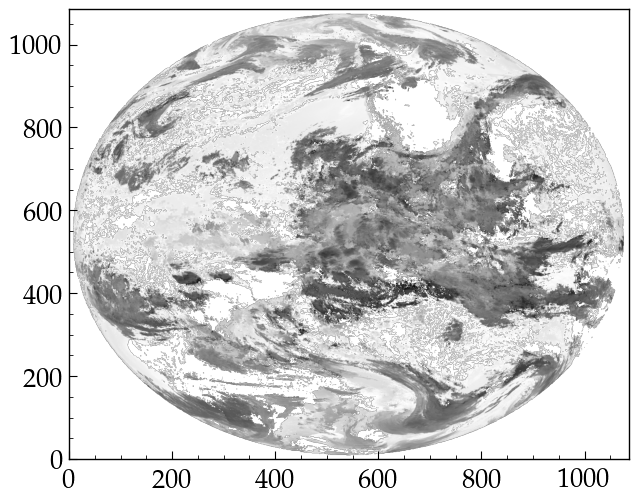

In [35]:
plt.imshow(ds_cl.HT)

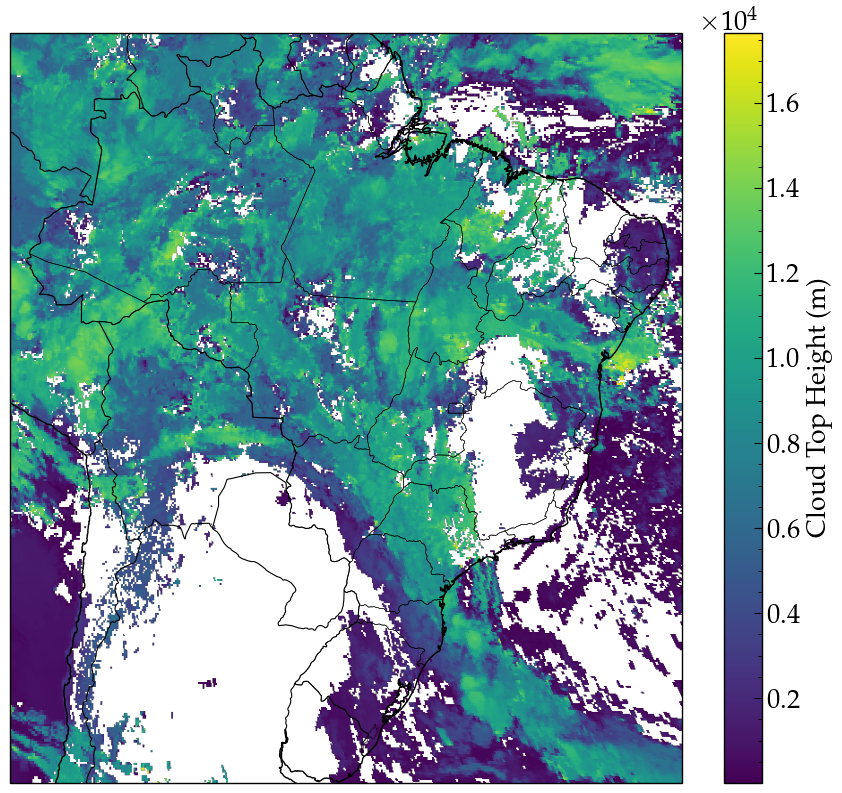

In [36]:
# 4. Plot in Mercator projection
fig_cl = plt.figure(figsize=(12, 10))

a_cl = plt.axes(projection=ccrs.Mercator())
a_cl.set_extent(BRAZIL_EXTENT, crs=ccrs.PlateCarree())

# GOES ABI data is in geostationary projection
im_cl = a_cl.imshow(
    ds_cl.HT,
    origin="upper",
    transform=ccrs.Geostationary(
        central_longitude=ds_cl.goes_imager_projection.longitude_of_projection_origin,
        satellite_height=ds_cl.goes_imager_projection.perspective_point_height
    ),
    cmap='viridis'
)

# 5. Add map features
a_cl.coastlines(resolution="10m", linewidth=1)
a_cl.add_feature(cfeature.BORDERS, linewidth=0.8)
a_cl.add_feature(cfeature.STATES, linewidth=0.4)

# display cmap scale
plt.colorbar(im_cl, ax=a_cl, orientation='vertical', label='Cloud Top Height (m)')

### Get GOES-19 Cloud Optical Depth product

In [37]:
df_files_cod = goes_nearesttime(
    attime=DATE,
    within=timedelta(hours=1),
    satellite="goes19",
    product="ABI-L2-COD",
    domain="F",
    return_as="filelist",
    save_dir=GOES_DIR
)

📦 Finished downloading [1] files to [goes_data_cache/noaa-goes19/ABI-L2-CODF].


In [38]:
df_files_cod

,file,product_mode,satellite,start,end,creation,product,mode_bands,mode,band
0,noaa-goes19/ABI-L2-CODF/2026/012/12/OR_ABI-L2-...,ABI-L2-CODF-M6,G19,2026-01-12 12:00:21.100,2026-01-12 12:09:52,2026-01-12 12:14:51.200,ABI-L2-CODF,M6,6,None


In [39]:
ds_cod = xr.open_dataset(f"{df_files_cod.attrs['filePath']}/{df_files_cod.file[0]}")

In [40]:
ds_cod

<xarray.Dataset> Size: 59MB
Dimensions:                                    (y: 2712, x: 2712,
                                                number_of_time_bounds: 2,
                                                number_of_image_bounds: 2,
                                                number_of_LZA_bounds: 2,
                                                number_of_SZA_bounds: 2)
Coordinates: (12/14)
  * y                                          (y) float32 11kB 0.1518 ... -0...
  * x                                          (x) float32 11kB -0.1518 ... 0...
    t                                          datetime64[ns] 8B ...
    y_image                                    float32 4B ...
    x_image                                    float32 4B ...
    cod_product_wavelength                     float32 4B ...
    ...                                         ...
    quantitative_local_zenith_angle            float32 4B ...
    day_solar_zenith_angle                     float32 4B ...
    night_solar_zenith_angle                   float32 4B ...
    twilight_solar_zenith_angle                float32 4B ...
    day_algorithm_solar_zenith_angle           float32 4B ...
    night_algorithm_solar_zenith_angle         float32 4B ...
Dimensions without coordinates: number_of_time_bounds, number_of_image_bounds,
                                number_of_LZA_bounds, number_of_SZA_bounds
Data variables: (12/38)
    COD                                        (y, x) float32 29MB ...
    DQF                                        (y, x) float32 29MB ...
    time_bounds                                (number_of_time_bounds) datetime64[ns] 16B ...
    goes_imager_projection                     int32 4B ...
    y_image_bounds                             (number_of_image_bounds) float32 8B ...
    x_image_bounds                             (number_of_image_bounds) float32 8B ...
    ...                                         ...
    quantitative_local_zenith_angle_bounds     (number_of_LZA_bounds) float32 8B ...
    day_solar_zenith_angle_bounds              (number_of_SZA_bounds) float32 8B ...
    night_solar_zenith_angle_bounds            (number_of_SZA_bounds) float32 8B ...
    twilight_solar_zenith_angle_bounds         (number_of_SZA_bounds) float32 8B ...
    day_algorithm_solar_zenith_angle_bounds    (number_of_SZA_bounds) float32 8B ...
    night_algorithm_solar_zenith_angle_bounds  (number_of_SZA_bounds) float32 8B ...
Attributes: (12/29)
    naming_authority:          gov.nesdis.noaa
    Conventions:               CF-1.7
    Metadata_Conventions:      Unidata Dataset Discovery v1.0
    standard_name_vocabulary:  CF Standard Name Table (v35, 20 July 2016)
    institution:               DOC/NOAA/NESDIS > U.S. Department of Commerce,...
    project:                   GOES
    ...                        ...
    date_created:              2026-01-12T12:14:51.2Z
    time_coverage_start:       2026-01-12T12:00:21.1Z
    time_coverage_end:         2026-01-12T12:09:52.0Z
    timeline_id:               ABI Mode 6
    production_data_source:    Realtime
    id:                        76306485-7468-4aab-8de0-5692999ed275

In [41]:
ds_cod.geospatial_lat_lon_extent

<xarray.DataArray 'geospatial_lat_lon_extent' ()> Size: 4B
[1 values with dtype=float32]
Coordinates:
    t                                   datetime64[ns] 8B ...
    y_image                             float32 4B ...
    x_image                             float32 4B ...
    cod_product_wavelength              float32 4B ...
    day_retrieval_local_zenith_angle    float32 4B ...
    night_retrieval_local_zenith_angle  float32 4B ...
    quantitative_local_zenith_angle     float32 4B ...
    day_solar_zenith_angle              float32 4B ...
    night_solar_zenith_angle            float32 4B ...
    twilight_solar_zenith_angle         float32 4B ...
    day_algorithm_solar_zenith_angle    float32 4B ...
    night_algorithm_solar_zenith_angle  float32 4B ...
Attributes:
    long_name:                       geospatial latitude and longitude refere...
    geospatial_westbound_longitude:  -156.2995
    geospatial_northbound_latitude:  81.3282
    geospatial_eastbound_longitude:  6.2995
    geospatial_southbound_latitude:  -81.3282
    geospatial_lat_center:           0.0
    geospatial_lon_center:           -75.0
    geospatial_lat_nadir:            0.0
    geospatial_lon_nadir:            -75.0
    geospatial_lat_units:            degrees_north
    geospatial_lon_units:            degrees_east

In [42]:
ds_cod.COD

<xarray.DataArray 'COD' (y: 2712, x: 2712)> Size: 29MB
[7354944 values with dtype=float32]
Coordinates: (12/14)
  * y                                   (y) float32 11kB 0.1518 ... -0.1518
  * x                                   (x) float32 11kB -0.1518 ... 0.1518
    t                                   datetime64[ns] 8B ...
    y_image                             float32 4B ...
    x_image                             float32 4B ...
    cod_product_wavelength              float32 4B ...
    ...                                  ...
    quantitative_local_zenith_angle     float32 4B ...
    day_solar_zenith_angle              float32 4B ...
    night_solar_zenith_angle            float32 4B ...
    twilight_solar_zenith_angle         float32 4B ...
    day_algorithm_solar_zenith_angle    float32 4B ...
    night_algorithm_solar_zenith_angle  float32 4B ...
Attributes:
    long_name:            ABI L2+ Cloud Optical Depth at 640 nm
    standard_name:        atmosphere_optical_thickness_due_to_cloud
    valid_range:          [    0 65530]
    units:                1
    resolution:           y: 0.000112 rad x: 0.000112 rad
    grid_mapping:         goes_imager_projection
    cell_methods:         day_retrieval_local_zenith_angle: point (good or de...
    ancillary_variables:  DQF

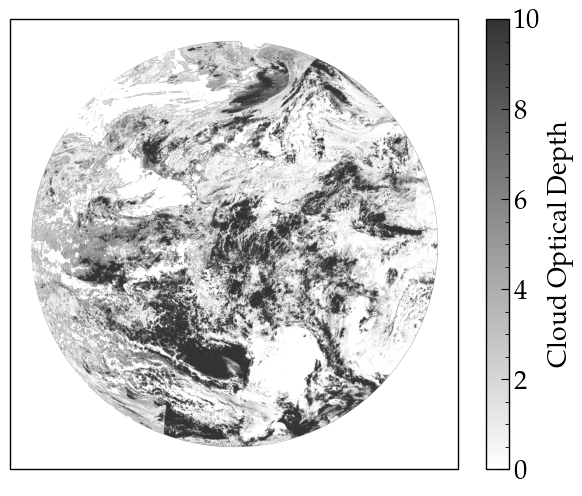

In [43]:
ax_cod = plt.subplot(projection=ccrs.Geostationary(
    central_longitude=ds_cod.goes_imager_projection.longitude_of_projection_origin,
    satellite_height=ds_cod.goes_imager_projection.perspective_point_height,
    sweep_axis='x'))
im_cod = ax_cod.imshow(np.clip(ds_cod.COD, 0, 10), origin='upper', alpha=0.8)
ax_cod.coastlines()

plt.colorbar(im_cod, ax=ax_cod, orientation='vertical', label='Cloud Optical Depth')

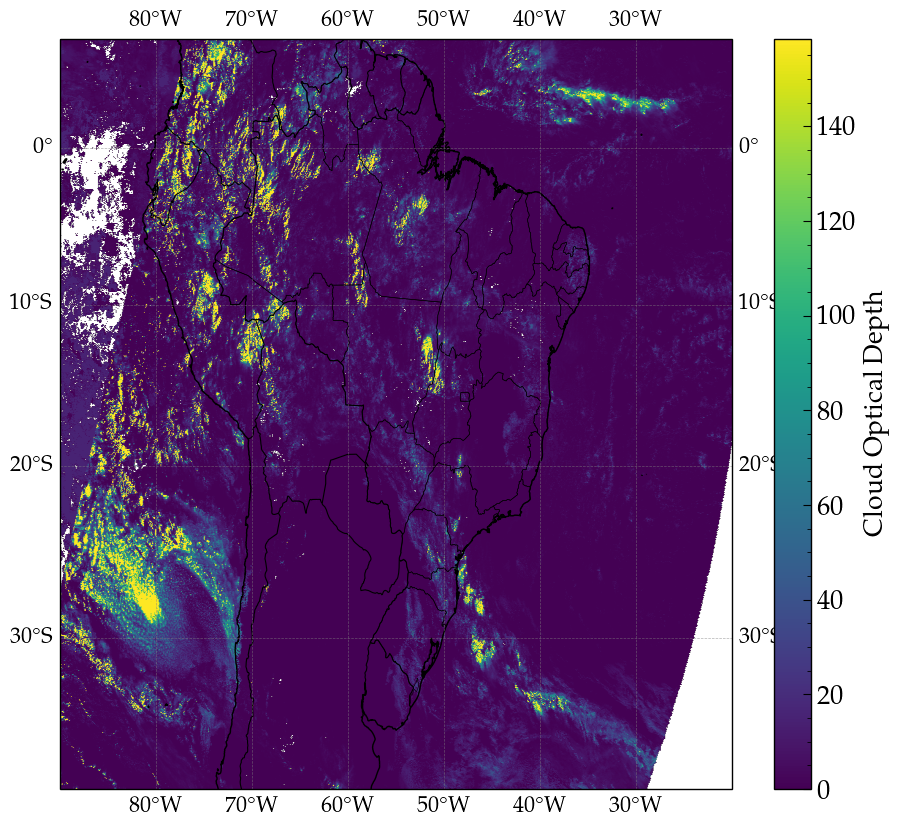

In [44]:
# 4. Plot in Mercator projection
fig = plt.figure(figsize=(12, 10))

ax = plt.axes(projection=ccrs.Mercator())
ax.set_extent([-90, -20, -38, 7], crs=ccrs.PlateCarree())

# GOES ABI data is in geostationary projection
im = ax.imshow(
    ds_cod.COD,
    origin="upper",
    transform=ccrs.Geostationary(
        central_longitude=ds_cod.goes_imager_projection.longitude_of_projection_origin,
        satellite_height=ds_cod.goes_imager_projection.perspective_point_height
    ),
    cmap='viridis'
)

# 5. Add map features
ax.coastlines(resolution="10m", linewidth=1)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)
ax.add_feature(cfeature.STATES, linewidth=0.4)

ax.gridlines(draw_labels=True, linestyle='--', alpha=0.6)

# display cmap scale
plt.colorbar(im, ax=ax, orientation='vertical', label='Cloud Optical Depth')

### Cloud top temperature

In [45]:
df_files_ctt = goes_nearesttime(
    attime=DATE,
    within=timedelta(hours=1),
    satellite="goes19",
    product="ABI-L2-ACHT",
    domain="F",
    return_as="filelist",
    save_dir=GOES_DIR
)

📦 Finished downloading [1] files to [goes_data_cache/noaa-goes19/ABI-L2-ACHTF].


In [46]:
df_files_ctt

,file,product_mode,satellite,start,end,creation,product,mode_bands,mode,band
0,noaa-goes19/ABI-L2-ACHTF/2026/012/12/OR_ABI-L2...,ABI-L2-ACHTF-M6,G19,2026-01-12 12:00:21.100,2026-01-12 12:09:52,2026-01-12 12:13:27.300,ABI-L2-ACHTF,M6,6,None


In [47]:
ds_ctt = xr.open_dataset(f"{df_files_ctt.attrs['filePath']}/{df_files_ctt.file[0]}")

In [48]:
ds_ctt

<xarray.Dataset> Size: 235MB
Dimensions:                                 (y: 5424, x: 5424,
                                             number_of_time_bounds: 2,
                                             number_of_image_bounds: 2,
                                             number_of_LZA_bounds: 2,
                                             number_of_SZA_bounds: 2)
Coordinates:
  * y                                       (y) float32 22kB 0.1518 ... -0.1518
  * x                                       (x) float32 22kB -0.1518 ... 0.1518
    t                                       datetime64[ns] 8B ...
    y_image                                 float32 4B ...
    x_image                                 float32 4B ...
    local_zenith_angle                      float32 4B ...
    solar_zenith_angle                      float32 4B ...
Dimensions without coordinates: number_of_time_bounds, number_of_image_bounds,
                                number_of_LZA_bounds, number_of_SZA_bounds
Data variables: (12/24)
    TEMP                                    (y, x) float32 118MB ...
    DQF                                     (y, x) float32 118MB ...
    time_bounds                             (number_of_time_bounds) datetime64[ns] 16B ...
    goes_imager_projection                  int32 4B ...
    y_image_bounds                          (number_of_image_bounds) float32 8B ...
    x_image_bounds                          (number_of_image_bounds) float32 8B ...
    ...                                      ...
    solar_zenith_angle_bounds               (number_of_SZA_bounds) float32 8B ...
    algorithm_dynamic_input_data_container  int32 4B ...
    processing_parm_version_container       int32 4B ...
    algorithm_product_version_container     int32 4B ...
    percent_uncorrectable_GRB_errors        float32 4B ...
    percent_uncorrectable_L0_errors         float32 4B ...
Attributes: (12/29)
    naming_authority:          gov.nesdis.noaa
    Conventions:               CF-1.7
    Metadata_Conventions:      Unidata Dataset Discovery v1.0
    standard_name_vocabulary:  CF Standard Name Table (v35, 20 July 2016)
    institution:               DOC/NOAA/NESDIS > U.S. Department of Commerce,...
    project:                   GOES
    ...                        ...
    date_created:              2026-01-12T12:13:27.3Z
    time_coverage_start:       2026-01-12T12:00:21.1Z
    time_coverage_end:         2026-01-12T12:09:52.0Z
    timeline_id:               ABI Mode 6
    production_data_source:    Realtime
    id:                        90408f0c-e970-4ce0-89d2-a14069d92e4e

In [49]:
ds_ctt.TEMP

<xarray.DataArray 'TEMP' (y: 5424, x: 5424)> Size: 118MB
[29419776 values with dtype=float32]
Coordinates:
  * y                   (y) float32 22kB 0.1518 0.1518 ... -0.1518 -0.1518
  * x                   (x) float32 22kB -0.1518 -0.1518 ... 0.1518 0.1518
    t                   datetime64[ns] 8B ...
    y_image             float32 4B ...
    x_image             float32 4B ...
    local_zenith_angle  float32 4B ...
    solar_zenith_angle  float32 4B ...
Attributes:
    long_name:            ABI L2+ Cloud Top Temperature
    standard_name:        air_temperature_at_cloud_top
    valid_range:          [    0 65530]
    units:                K
    resolution:           y: 0.000056 rad x: 0.000056 rad
    grid_mapping:         goes_imager_projection
    cell_methods:         local_zenith_angle: point (good quality pixel produ...
    ancillary_variables:  DQF

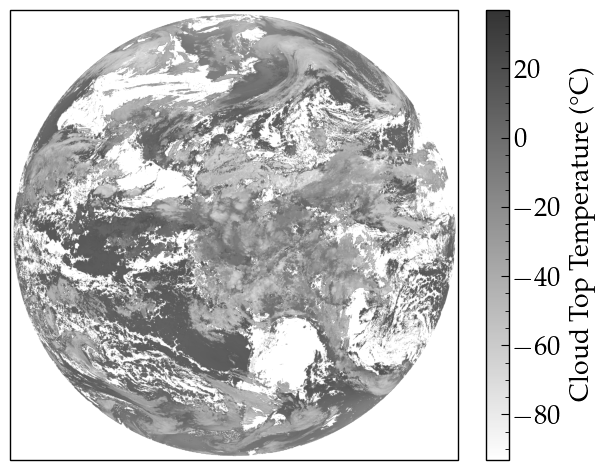

In [50]:
ax_ctt = plt.subplot(projection=ccrs.Geostationary(
    central_longitude=ds_ctt.goes_imager_projection.longitude_of_projection_origin,
    satellite_height=ds_ctt.goes_imager_projection.perspective_point_height,
    sweep_axis='x'))
im_ctt =ax_ctt.imshow((ds_ctt.TEMP - 273.15), origin='upper', alpha=0.8)
ax_ctt.coastlines()

plt.colorbar(im_ctt, ax=ax_ctt, orientation='vertical', label='Cloud Top Temperature (°C)')

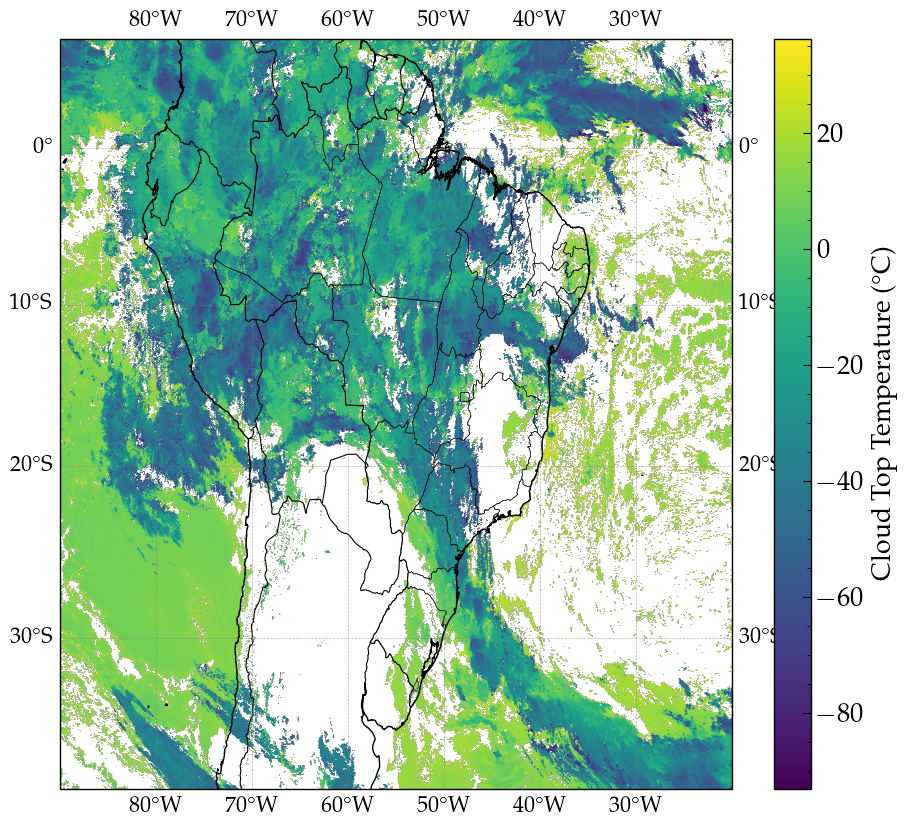

In [51]:
# Plot in Mercator projection
fig_ctt = plt.figure(figsize=(12, 10))

a_ctt = plt.axes(projection=ccrs.Mercator())
a_ctt.set_extent([-90, -20, -38, 7], crs=ccrs.PlateCarree())

# GOES ABI data is in geostationary projection
im_ctt = a_ctt.imshow(
    ds_ctt.TEMP - 273.15,
    origin="upper",
    transform=ccrs.Geostationary(
        central_longitude=ds_ctt.goes_imager_projection.longitude_of_projection_origin,
        satellite_height=ds_ctt.goes_imager_projection.perspective_point_height
    ),
    cmap='viridis'
)

# 5. Add map features
a_ctt.coastlines(resolution="10m", linewidth=1)
a_ctt.add_feature(cfeature.BORDERS, linewidth=0.8)
a_ctt.add_feature(cfeature.STATES, linewidth=0.4)

a_ctt.gridlines(draw_labels=True, linestyle='--', alpha=0.6)

# display cmap scale
plt.colorbar(im_ctt, ax=a_ctt, orientation='vertical', label='Cloud Top Temperature (°C)')